In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


In [2]:

df = pd.read_csv("Churn_Modelling.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [3]:

print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nTarget distribution:")
print(df["Exited"].value_counts())


Column names:
['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  flo

In [4]:

print("Missing values before cleaning:")
print(df.isnull().sum().sum())

print("Duplicate rows before cleaning:", df.duplicated().sum())

df = df.drop_duplicates().copy()

columns_to_drop = ["RowNumber", "CustomerId", "Surname"]
df = df.drop(
    columns=[col for col in columns_to_drop if col in df.columns]
)

print("\nShape after cleaning:", df.shape)
print("\nRemaining missing values:")
print(df.isnull().sum())


Missing values before cleaning:
0
Duplicate rows before cleaning: 0

Shape after cleaning: (10000, 11)

Remaining missing values:
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64


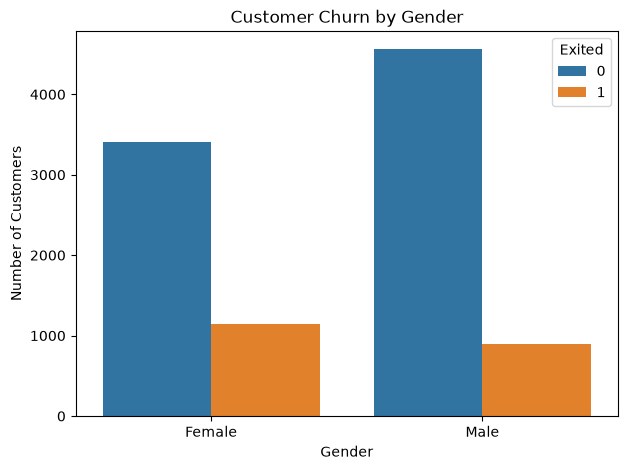

In [5]:

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Gender", hue="Exited")

plt.title("Customer Churn by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")
plt.show()


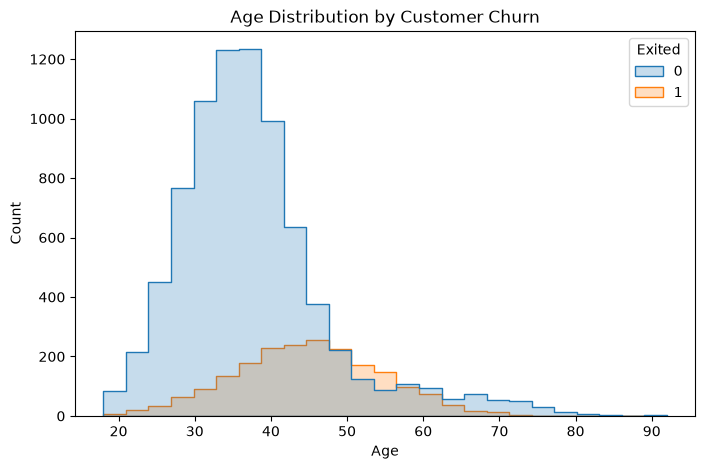

In [6]:

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Age",
    hue="Exited",
    bins=25,
    multiple="layer",
    element="step"
)

plt.title("Age Distribution by Customer Churn")
plt.show()


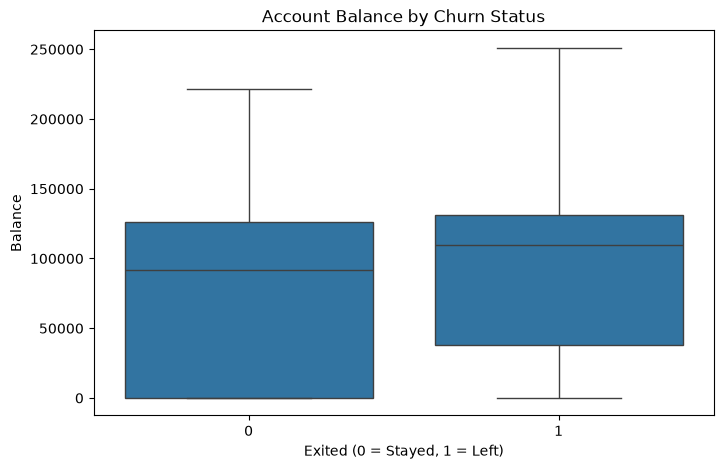

In [7]:

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Exited", y="Balance")

plt.title("Account Balance by Churn Status")
plt.xlabel("Exited (0 = Stayed, 1 = Left)")
plt.show()


In [8]:

df_encoded = pd.get_dummies(
    df,
    columns=["Geography"],
    drop_first=True,
    dtype=int
)

df_encoded["Gender"] = df_encoded["Gender"].map({
    "Female": 0,
    "Male": 1
})

print("Encoded dataset:")
display(df_encoded.head())

print("\nEncoded columns:")
print(df_encoded.columns.tolist())


Encoded dataset:


,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain
0,619,0,42,2,0.00,1,1,1,101348.88,1,0,0
1,608,0,41,1,83807.86,1,0,1,112542.58,0,0,1
2,502,0,42,8,159660.80,3,1,0,113931.57,1,0,0
3,699,0,39,1,0.00,2,0,0,93826.63,0,0,0
4,850,0,43,2,125510.82,1,1,1,79084.10,0,0,1



Encoded columns:
['CreditScore', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited', 'Geography_Germany', 'Geography_Spain']


In [9]:

X = df_encoded.drop("Exited", axis=1)
y = df_encoded["Exited"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)


Features shape: (10000, 11)
Target shape: (10000,)


In [10]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


Training samples: 8000
Testing samples: 2000


In [11]:

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")


Feature scaling completed!


In [12]:

model = LogisticRegression(max_iter=1000)

model.fit(X_train_scaled, y_train)

print("Model training completed!")


Model training completed!


In [13]:

y_pred = model.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy:.4f}")
print(f"Model Accuracy Percentage: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


Model Accuracy: 0.8080
Model Accuracy Percentage: 80.80%

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.97      0.89      1593
           1       0.59      0.19      0.28       407

    accuracy                           0.81      2000
   macro avg       0.71      0.58      0.59      2000
weighted avg       0.78      0.81      0.77      2000



In [17]:

import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report
)

print("Imports successful!")


Imports successful!


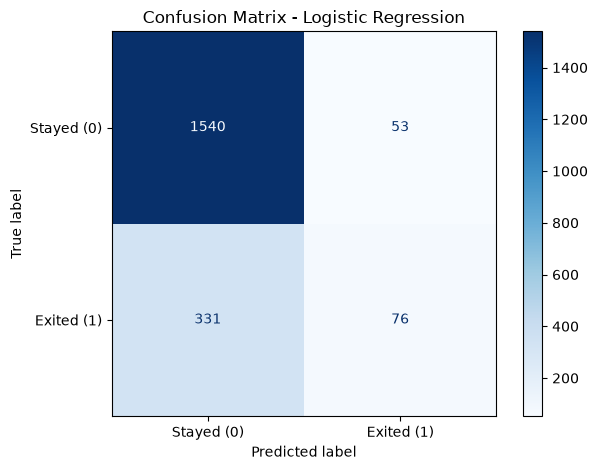

In [18]:

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stayed (0)", "Exited (1)"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Logistic Regression")
plt.tight_layout()
plt.show()


Feature Importance:
          Feature  Coefficient  Absolute Importance
              Age     0.738847             0.738847
   IsActiveMember    -0.515485             0.515485
Geography_Germany     0.356679             0.356679
           Gender    -0.260851             0.260851
          Balance     0.160622             0.160622
      CreditScore    -0.085986             0.085986
    NumOfProducts    -0.070292             0.070292
  EstimatedSalary     0.047725             0.047725
        HasCrCard    -0.032208             0.032208
           Tenure    -0.020071             0.020071
  Geography_Spain     0.018907             0.018907


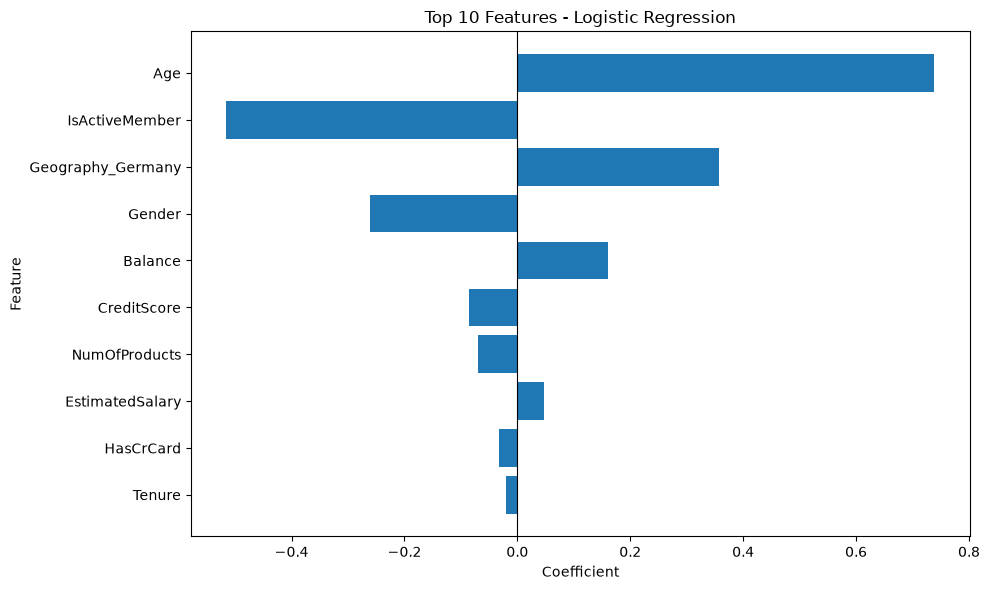

In [19]:

# Analyze Logistic Regression coefficients

importance = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_[0]
})

importance["Absolute Importance"] = importance["Coefficient"].abs()

importance = importance.sort_values(
    by="Absolute Importance",
    ascending=False
)

print("Feature Importance:")
print(importance.to_string(index=False))

# Visualize the top 10 features

top_features = importance.head(10).sort_values(
    by="Absolute Importance"
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)

plt.axvline(0, color="black", linewidth=0.8)
plt.title("Top 10 Features - Logistic Regression")
plt.xlabel("Coefficient")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [20]:

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
rf_pred = rf_model.predict(X_test)

print("Random Forest model trained successfully!")


Random Forest model trained successfully!


In [21]:

rf_accuracy = accuracy_score(y_test, rf_pred)

print(f"Random Forest Accuracy: {rf_accuracy:.4f}")
print(f"Random Forest Accuracy: {rf_accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_pred,
    zero_division=0
))


Random Forest Accuracy: 0.8445
Random Forest Accuracy: 84.45%

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.91      0.90      1593
           1       0.62      0.59      0.61       407

    accuracy                           0.84      2000
   macro avg       0.76      0.75      0.75      2000
weighted avg       0.84      0.84      0.84      2000



              Model  Accuracy  Accuracy (%)
Logistic Regression    0.8080         80.80
      Random Forest    0.8445         84.45


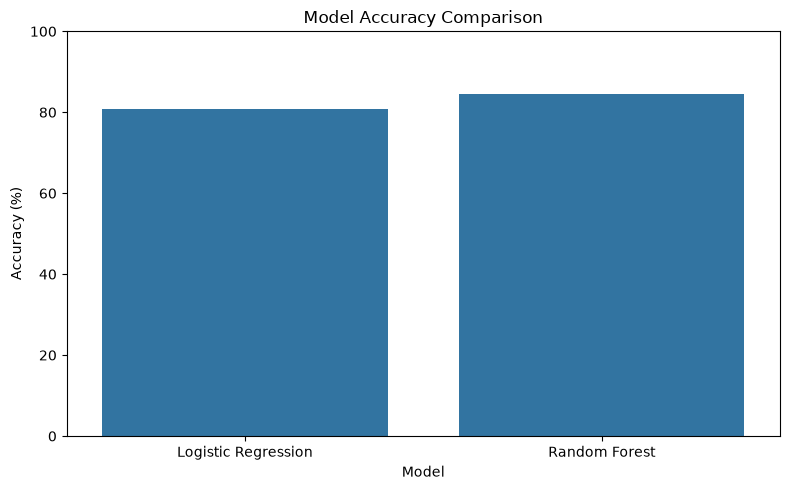

In [22]:

results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, rf_pred)
    ]
})

results["Accuracy (%)"] = results["Accuracy"] * 100

print(results.to_string(index=False))

plt.figure(figsize=(8, 5))

sns.barplot(
    data=results,
    x="Model",
    y="Accuracy (%)"
)

plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


          Feature  Importance
              Age    0.253890
          Balance    0.143257
  EstimatedSalary    0.138281
      CreditScore    0.134742
    NumOfProducts    0.128007
           Tenure    0.080528
   IsActiveMember    0.035883
Geography_Germany    0.032265
           Gender    0.020240
        HasCrCard    0.018071
  Geography_Spain    0.014837


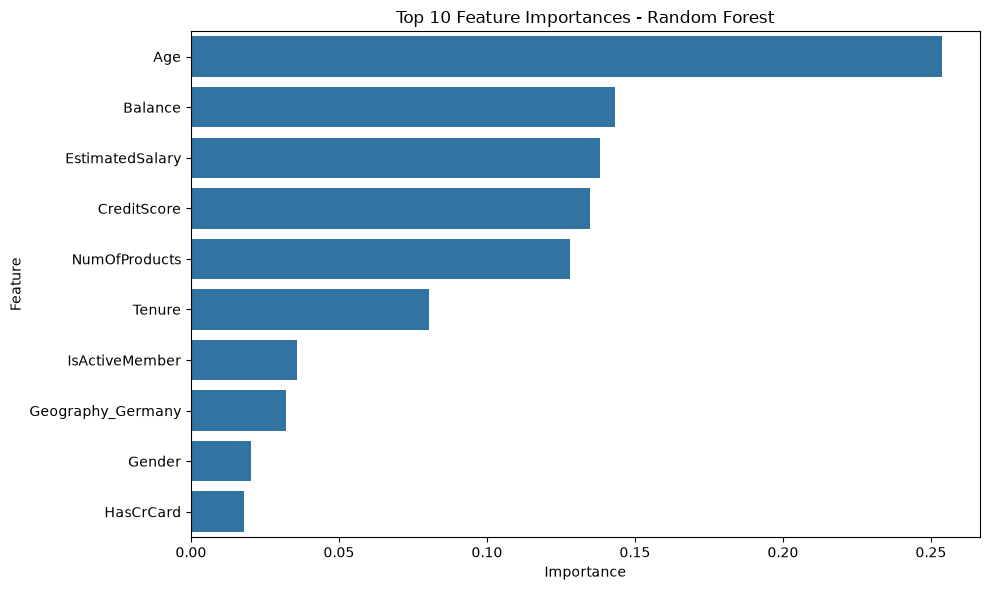

In [23]:

rf_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

rf_importance = rf_importance.sort_values(
    by="Importance",
    ascending=False
)

print(rf_importance.to_string(index=False))

plt.figure(figsize=(10, 6))

sns.barplot(
    data=rf_importance.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Feature Importances - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


## Conclusion

In this project, I developed a Customer Churn Prediction system using the Churn Modelling dataset.

The dataset was inspected and cleaned, unnecessary columns were removed, missing values were handled, and categorical features were encoded. Exploratory Data Analysis was performed to examine churn patterns across customer characteristics.

Logistic Regression was trained and evaluated using accuracy, a classification report, and a confusion matrix. A Random Forest classifier was also trained to compare model performance. Feature coefficients and feature importance were analyzed to identify variables associated with the models' predictions.

The Logistic Regression model achieved an accuracy of **[insert actual accuracy]%**, while the Random Forest model achieved an accuracy of **[insert actual accuracy]%**.

This project demonstrates how classification models can support customer retention analysis. Further evaluation of recall, precision, F1-score, and real-world performance would be needed before using the model for business decisions.